# 実験結果の可視化（ex001_kodak_cae）

`outputs/` を再帰的に走査し，学習曲線（同一条件の全 seed の平均と標準偏差）と，Kodak 24 枚による Figure 4 形式のレート・歪み曲線を作成する．図は `outputs/ex001_kodak_cae/figures/` に保存する．

In [1]:
import glob, json, os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = os.path.abspath(".")
sys.path.append(os.path.join(ROOT, "programs", "ex001_kodak_cae"))
EXPERIMENTS = ["ex001_kodak_cae"]          # 可視化する実験（複数可）
METHODS = ["CAE"]                          # 比較手法
HPARAMS = ["0.01_96", "0.05_96", "0.2_64"] # 可視化するハイパーパラメータ（alpha_channels）
METRICS = ["loss", "psnr", "bpp_noisy", "rate_term", "dist_term"]

In [2]:
def load_logs():
    """outputs/ 以下の log.json を読み込み，(実験, 手法, ハイパーパラメータ) -> seed ごとの DataFrame のリストを返す．"""
    logs = {}
    for exp in EXPERIMENTS:
        for path in sorted(glob.glob(os.path.join(ROOT, "outputs", exp, "*", "*", "*", "log.json"))):
            seed_dir = os.path.dirname(path)
            hp_dir = os.path.dirname(seed_dir)
            method = os.path.basename(os.path.dirname(hp_dir))
            hp = os.path.basename(hp_dir)
            if method not in METHODS or hp not in HPARAMS:
                continue
            with open(path) as f:
                logs.setdefault((exp, method, hp), []).append(pd.DataFrame(json.load(f)))
    return logs

logs = load_logs()
{k: [len(d) for d in v] for k, v in logs.items()}

{('ex001_kodak_cae', 'CAE', '0.01_96'): [201],
 ('ex001_kodak_cae', 'CAE', '0.05_96'): [201],
 ('ex001_kodak_cae', 'CAE', '0.2_64'): [201]}

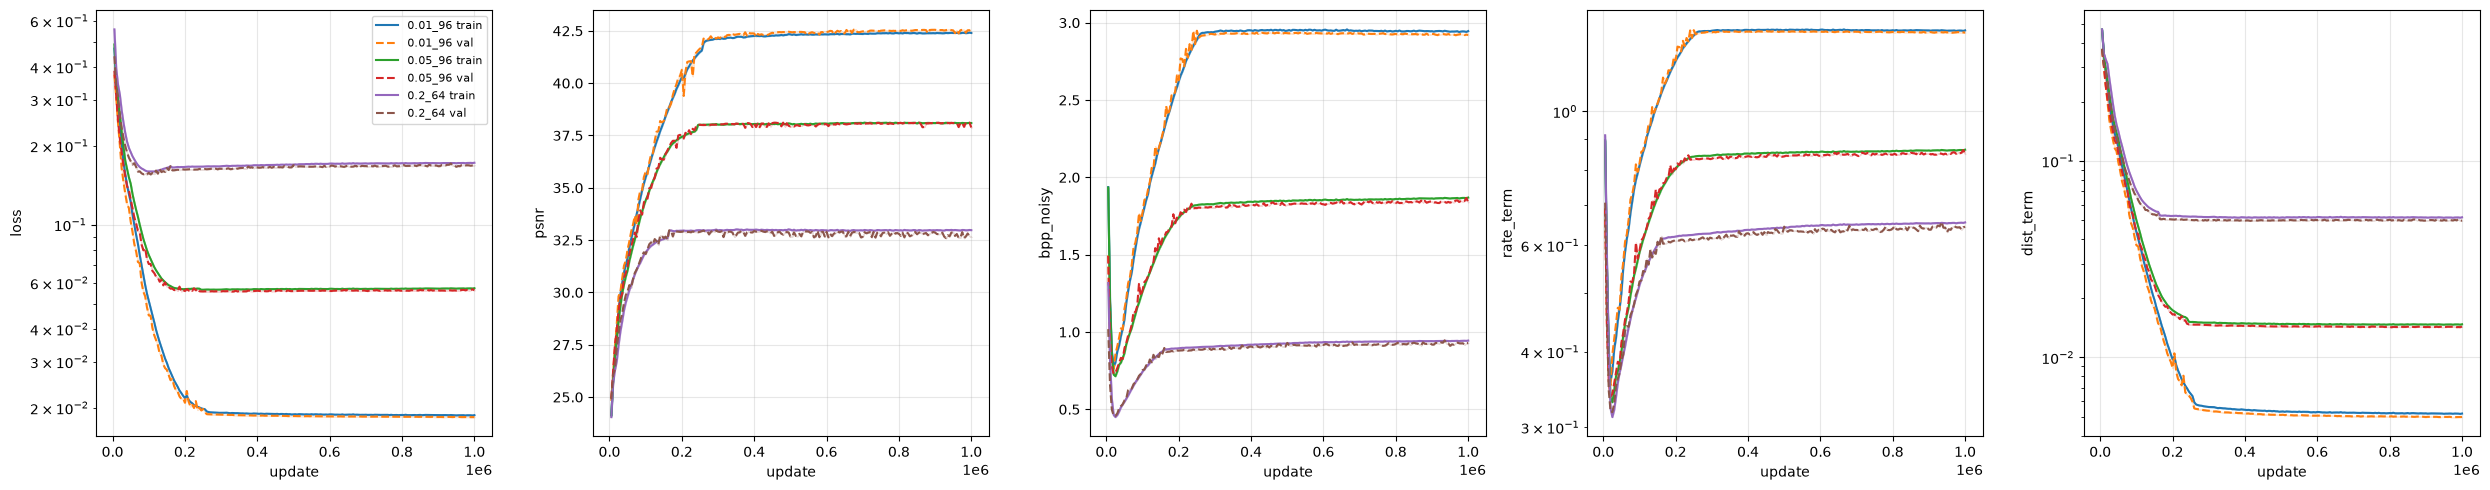

In [3]:
def plot_learning_curves(logs, metrics=METRICS):
    """学習・検証の各指標を更新数に対してプロットする（seed 間の平均 ± 標準偏差）．"""
    fig, axes = plt.subplots(1, len(metrics), figsize=(5 * len(metrics), 5))
    for ax, m in zip(axes, metrics):
        for (exp, method, hp), runs in logs.items():
            n = min(len(r) for r in runs)
            step = runs[0]["global_step"].values[:n]
            for split, ls in [("train", "-"), ("val", "--")]:
                vals = np.stack([r[f"{split}_{m}"].values[:n] for r in runs])
                mean, std = vals.mean(0), vals.std(0)
                line, = ax.plot(step[1:], mean[1:], ls, label=f"{hp} {split}")
                ax.fill_between(step[1:], (mean - std)[1:], (mean + std)[1:], color=line.get_color(), alpha=0.2)
        ax.set_xlabel("update"); ax.set_ylabel(m); ax.grid(alpha=0.3)
        if m in ("loss", "rate_term", "dist_term"):
            ax.set_yscale("log")
    axes[0].legend(fontsize=8)
    fig.tight_layout()
    return fig

fig = plot_learning_curves(logs)
os.makedirs(os.path.join(ROOT, "outputs", "ex001_kodak_cae", "figures"), exist_ok=True)
fig.savefig(os.path.join(ROOT, "outputs", "ex001_kodak_cae", "figures", "learning_curves.png"), dpi=150)

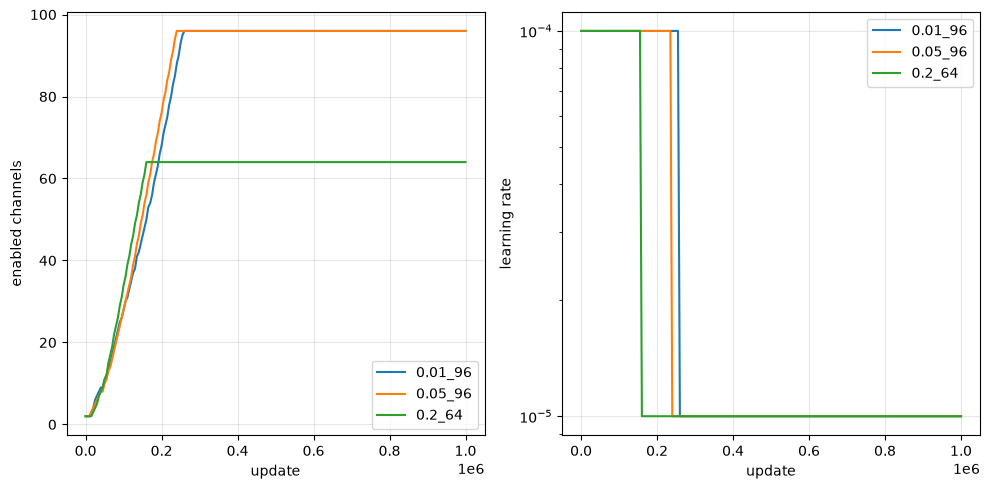

In [4]:
def plot_incremental(logs):
    """Incremental Training で有効化されたチャネル数と学習率の推移をプロットする．"""
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    for (exp, method, hp), runs in logs.items():
        r = runs[0]
        axes[0].plot(r["global_step"], r["enabled"], label=hp)
        axes[1].plot(r["global_step"], r["lr"], label=hp)
    axes[0].set_ylabel("enabled channels"); axes[1].set_ylabel("learning rate"); axes[1].set_yscale("log")
    for ax in axes:
        ax.set_xlabel("update"); ax.grid(alpha=0.3); ax.legend()
    fig.tight_layout()
    return fig

fig = plot_incremental(logs)
fig.savefig(os.path.join(ROOT, "outputs", "ex001_kodak_cae", "figures", "incremental_training.png"), dpi=150)

saved: /home/user/workspace/theis-cae/outputs/ex001_kodak_cae/figures


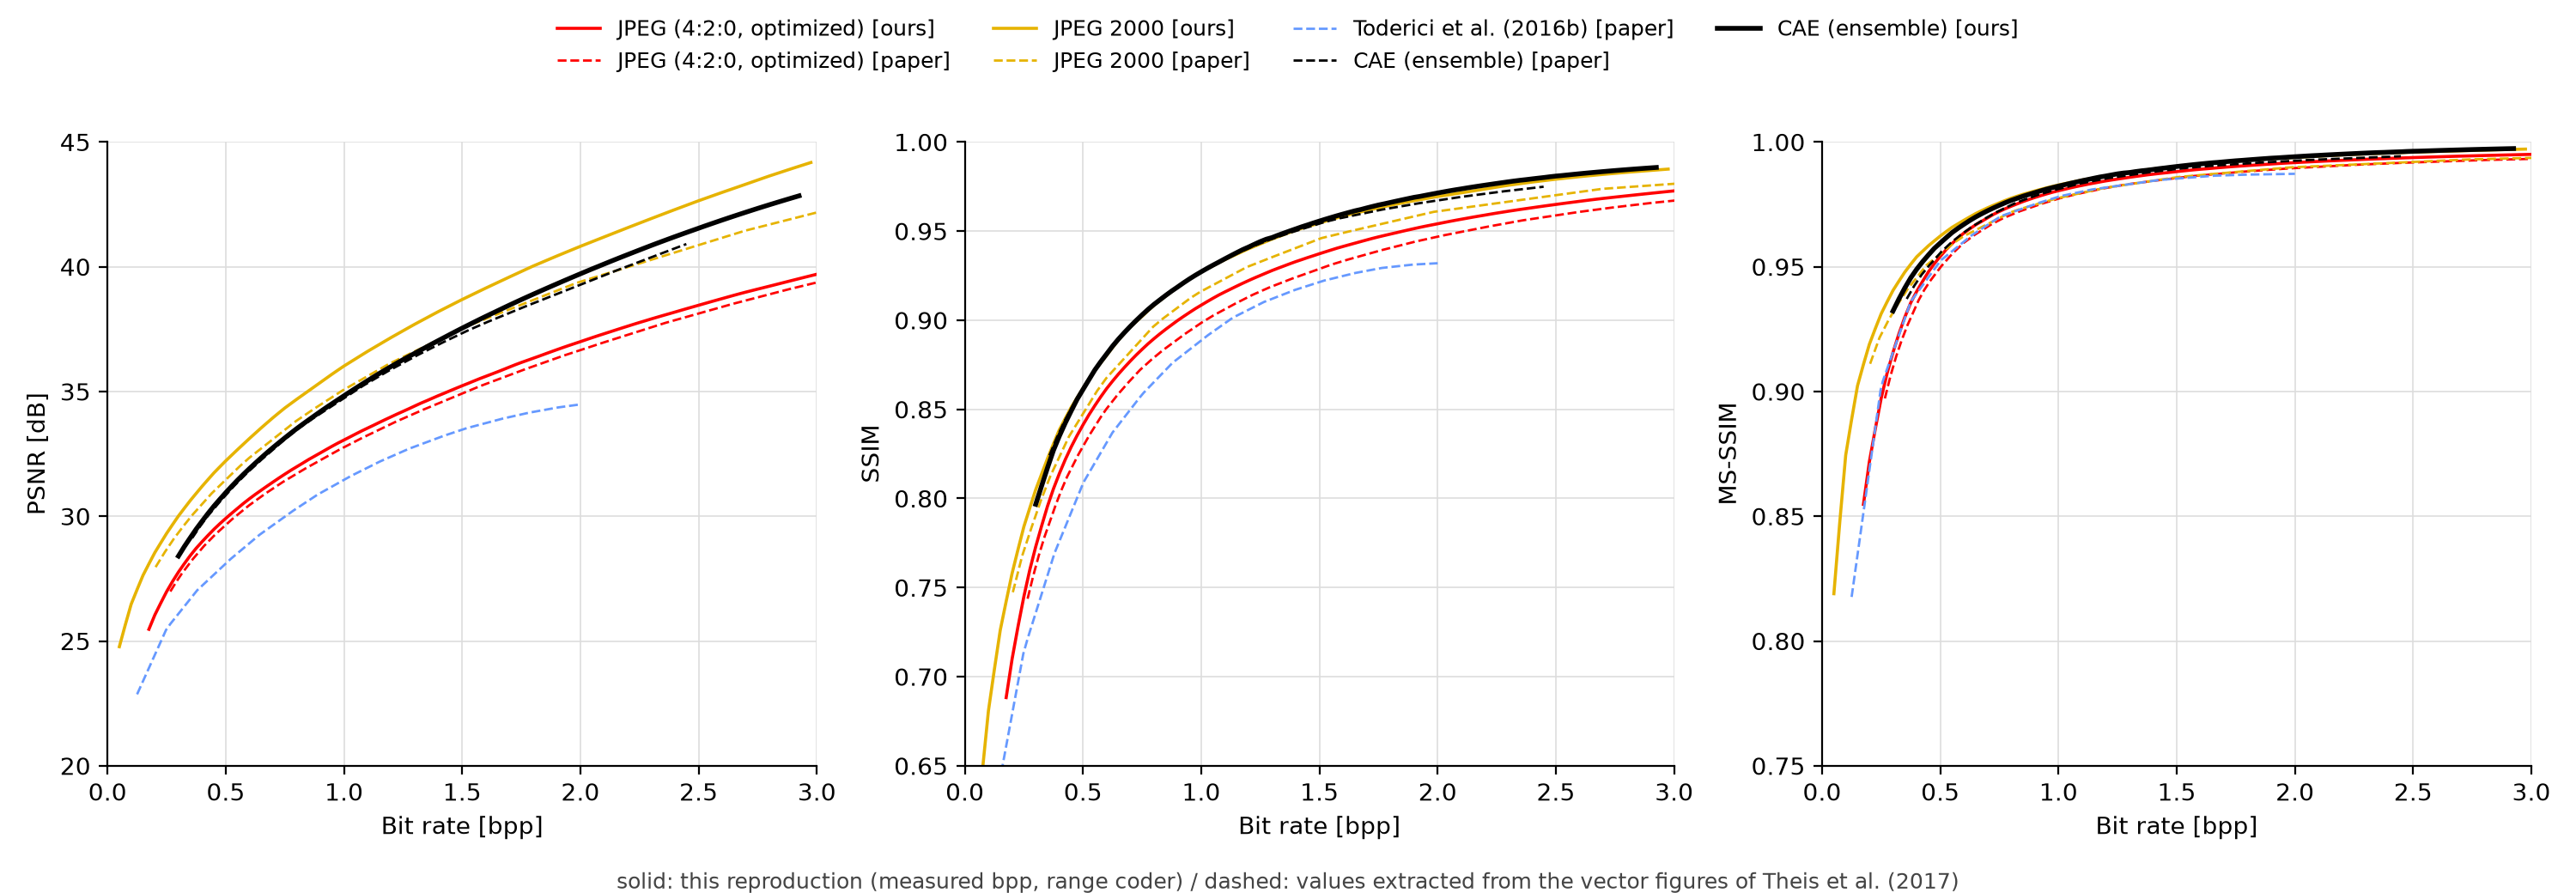

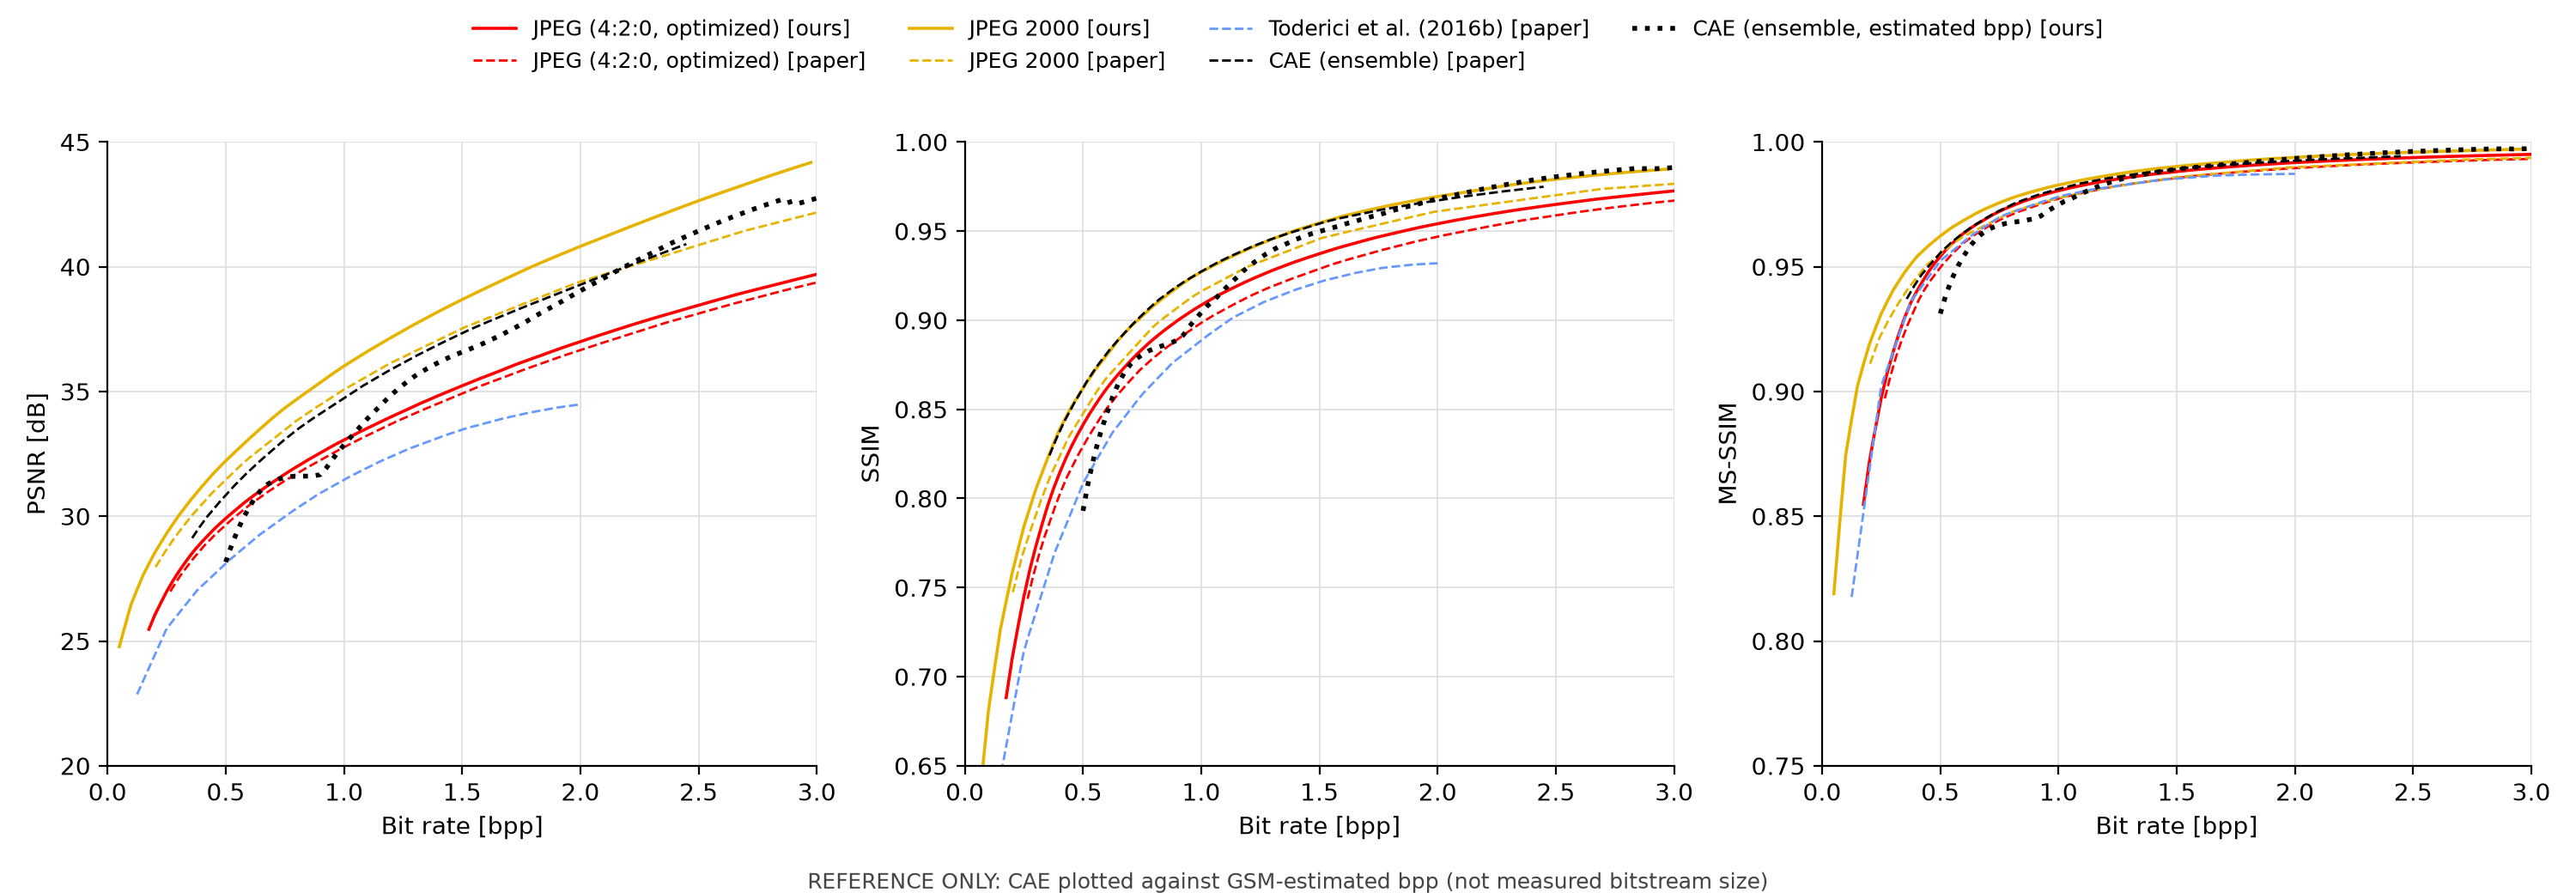

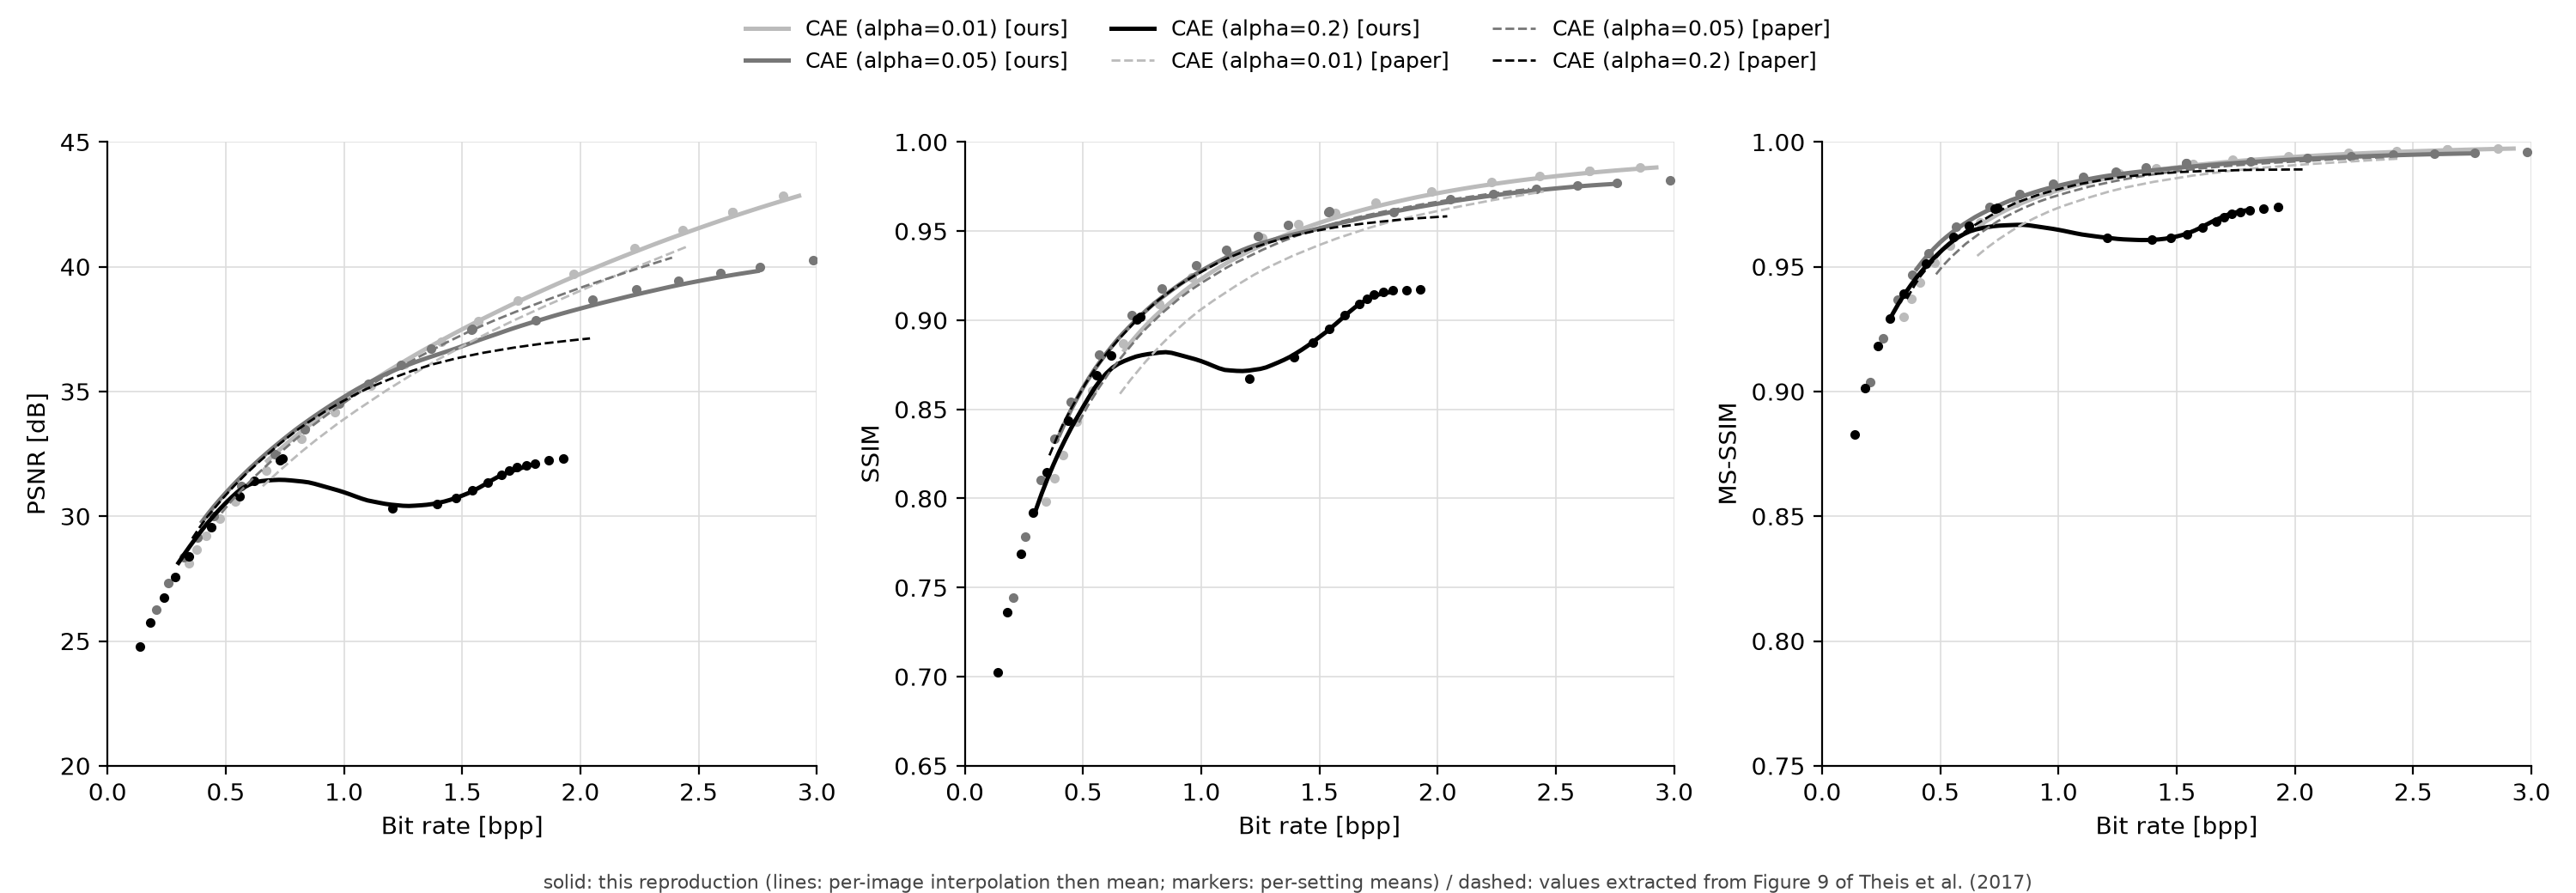

In [5]:
# Figure 4 / Figure 9 形式のレート・歪み曲線（Kodak 24 枚）
import plot_figure4
plot_figure4.main()
from IPython.display import Image, display
for name in ["figure4.png", "figure4_estimated.png", "figure9.png"]:
    p = os.path.join(ROOT, "outputs", "ex001_kodak_cae", "figures", name)
    if os.path.exists(p):
        display(Image(p))